In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

#OUTPUT_DIR = Path("./eval_tracking_subject12_ancien")

OUTPUT_DIR = Path("./eval_tracking_subject12")
summary_activity_path = OUTPUT_DIR / "summary_per_activity.csv"
summary_sequence_path = OUTPUT_DIR / "summary_per_sequence.csv"

In [2]:
df_activity = pd.read_csv(summary_activity_path)
df_sequence = pd.read_csv(summary_sequence_path)

print("summary_per_activity.csv")
display(df_activity.head())

print("\nsummary_per_sequence.csv")
display(df_sequence.head())

summary_per_activity.csv


,activity,n_frames,n_gt,n_pred,matches,FP,FN,IDs,FM,precision,recall,mota,motp,idf1,idp,idr,MT,PT,ML
0,CMJump_01_51433950,1629.0,2465.0,2387.0,2385.0,0.0,78.0,2.0,35.0,1.000000,0.968357,0.967546,0.014030,0.980627,0.996649,0.965112,6.0,0.0,0.0
1,CMJump_02_51433950,2288.0,3458.0,3225.0,3189.0,32.0,265.0,4.0,68.0,0.990078,0.923366,0.912955,0.016883,0.913362,0.946357,0.882591,4.0,2.0,0.0
2,CMJump_03_51433950,2635.0,4950.0,4701.0,4699.0,0.0,249.0,2.0,38.0,1.000000,0.949697,0.949293,0.003359,0.973992,0.999787,0.949495,7.0,2.0,0.0
3,Deadlift_01_51433950,1951.0,2941.0,2851.0,2847.0,4.0,94.0,0.0,31.0,0.998597,0.968038,0.966678,0.019836,0.983080,0.998597,0.968038,6.0,0.0,0.0



summary_per_sequence.csv


,Unnamed: 0,n_frames,n_gt,n_pred,matches,IDs,FM,MT,PT,ML,FP,FN,precision,recall,mota,motp,idf1,idp,idr
0,CMJump_01_51433950_cam00,385,385,385,384,1,0,1,0,0,0,0,1.0,1.000000,0.997403,0.000000,0.997403,0.997403,0.997403
1,CMJump_01_51433950_cam01,418,1254,1176,1175,1,35,3,0,0,0,78,1.0,0.937799,0.937002,0.028445,0.962140,0.994048,0.932217
2,CMJump_01_51433950_cam02,417,417,417,417,0,0,1,0,0,0,0,1.0,1.000000,1.000000,0.000092,1.000000,1.000000,1.000000
3,CMJump_01_51433950_cam03,409,409,409,409,0,0,1,0,0,0,0,1.0,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000
4,CMJump_02_51433950_cam00,540,540,540,540,0,0,1,0,0,0,0,1.0,1.000000,1.000000,0.017675,1.000000,1.000000,1.000000


In [3]:
print("Colonnes summary_per_activity:")
print(df_activity.columns.tolist())

print("\nColonnes summary_per_sequence:")
print(df_sequence.columns.tolist())

Colonnes summary_per_activity:
['activity', 'n_frames', 'n_gt', 'n_pred', 'matches', 'FP', 'FN', 'IDs', 'FM', 'precision', 'recall', 'mota', 'motp', 'idf1', 'idp', 'idr', 'MT', 'PT', 'ML']

Colonnes summary_per_sequence:
['Unnamed: 0', 'n_frames', 'n_gt', 'n_pred', 'matches', 'IDs', 'FM', 'MT', 'PT', 'ML', 'FP', 'FN', 'precision', 'recall', 'mota', 'motp', 'idf1', 'idp', 'idr']


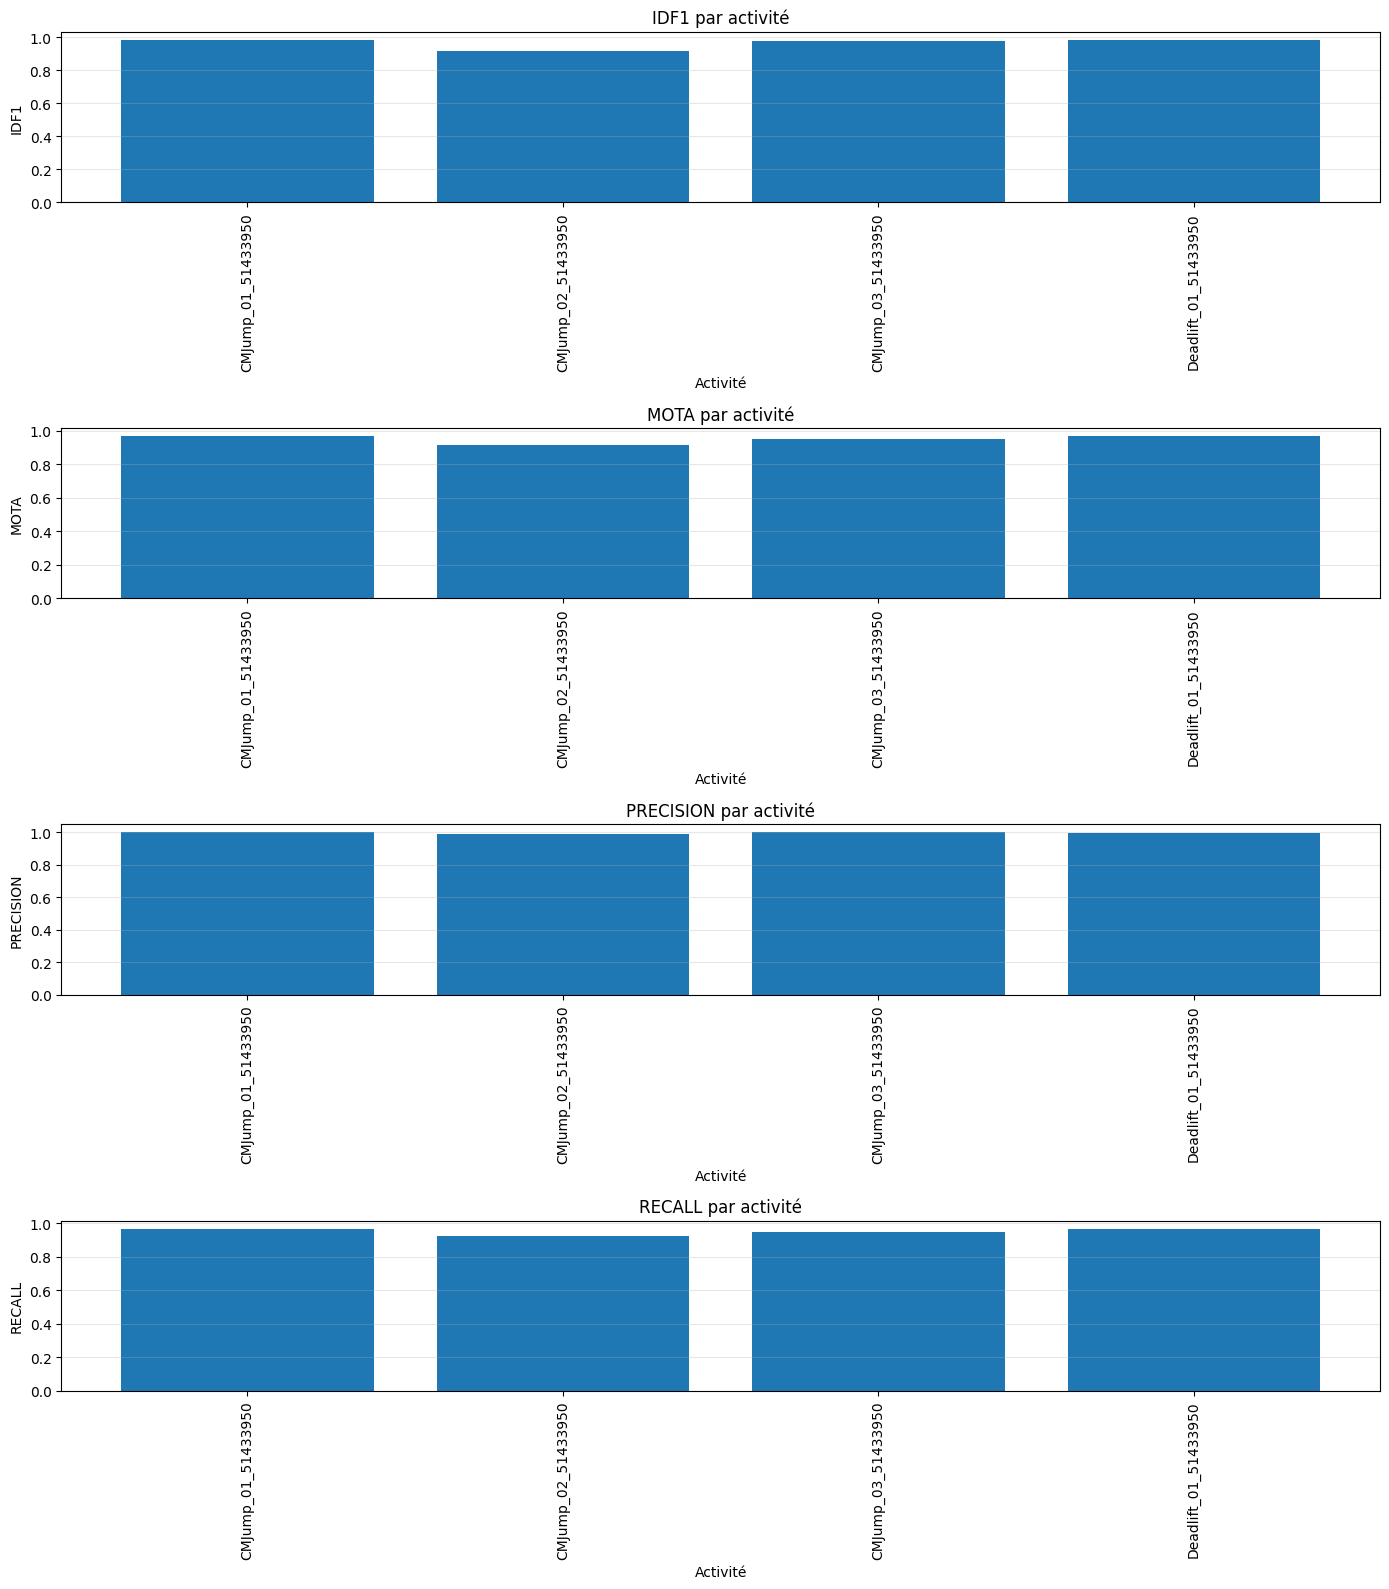

In [4]:
metrics_to_plot = ["idf1", "mota", "precision", "recall"]

df_plot = df_activity.copy()
df_plot = df_plot.sort_values("activity").reset_index(drop=True)

fig, axes = plt.subplots(len(metrics_to_plot), 1, figsize=(14, 4 * len(metrics_to_plot)))

if len(metrics_to_plot) == 1:
    axes = [axes]

for ax, metric in zip(axes, metrics_to_plot):
    if metric not in df_plot.columns:
        ax.set_visible(False)
        continue

    ax.bar(df_plot["activity"], df_plot[metric])
    ax.set_title(f"{metric.upper()} par activité")
    ax.set_ylabel(metric.upper())
    ax.set_xlabel("Activité")
    ax.tick_params(axis="x", rotation=90)
    ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

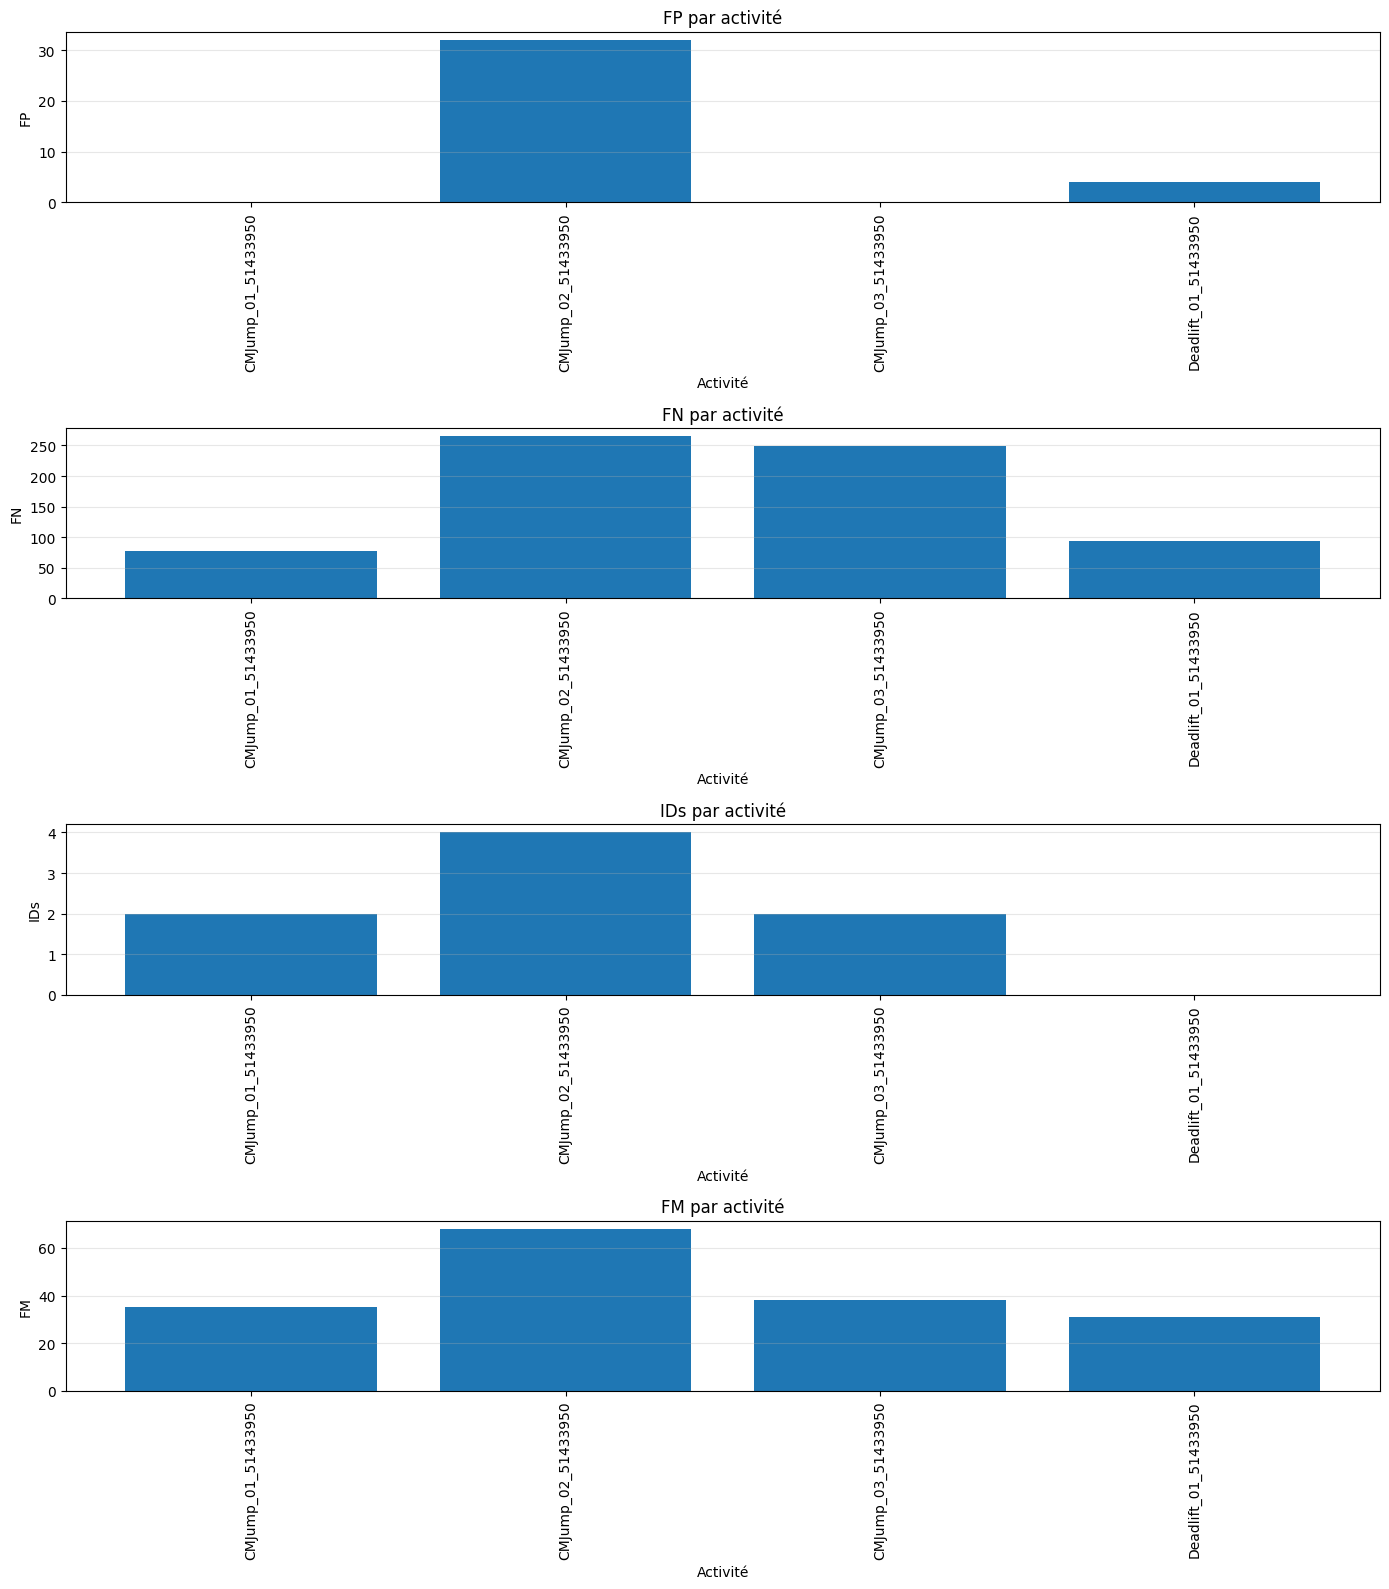

In [5]:
error_metrics = ["FP", "FN", "IDs", "FM"]

df_plot = df_activity.copy()
df_plot = df_plot.sort_values("activity").reset_index(drop=True)

fig, axes = plt.subplots(len(error_metrics), 1, figsize=(14, 4 * len(error_metrics)))

if len(error_metrics) == 1:
    axes = [axes]

for ax, metric in zip(axes, error_metrics):
    if metric not in df_plot.columns:
        ax.set_visible(False)
        continue

    ax.bar(df_plot["activity"], df_plot[metric])
    ax.set_title(f"{metric} par activité")
    ax.set_ylabel(metric)
    ax.set_xlabel("Activité")
    ax.tick_params(axis="x", rotation=90)
    ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
df_activity_sorted = df_activity.sort_values("idf1", ascending=False).reset_index(drop=True)
display(df_activity_sorted[["activity", "idf1", "mota", "precision", "recall", "FP", "FN", "IDs", "FM"]])

,activity,idf1,mota,precision,recall,FP,FN,IDs,FM
0,Deadlift_01_51433950,0.983080,0.966678,0.998597,0.968038,4.0,94.0,0.0,31.0
1,CMJump_01_51433950,0.980627,0.967546,1.000000,0.968357,0.0,78.0,2.0,35.0
2,CMJump_03_51433950,0.973992,0.949293,1.000000,0.949697,0.0,249.0,2.0,38.0
3,CMJump_02_51433950,0.913362,0.912955,0.990078,0.923366,32.0,265.0,4.0,68.0


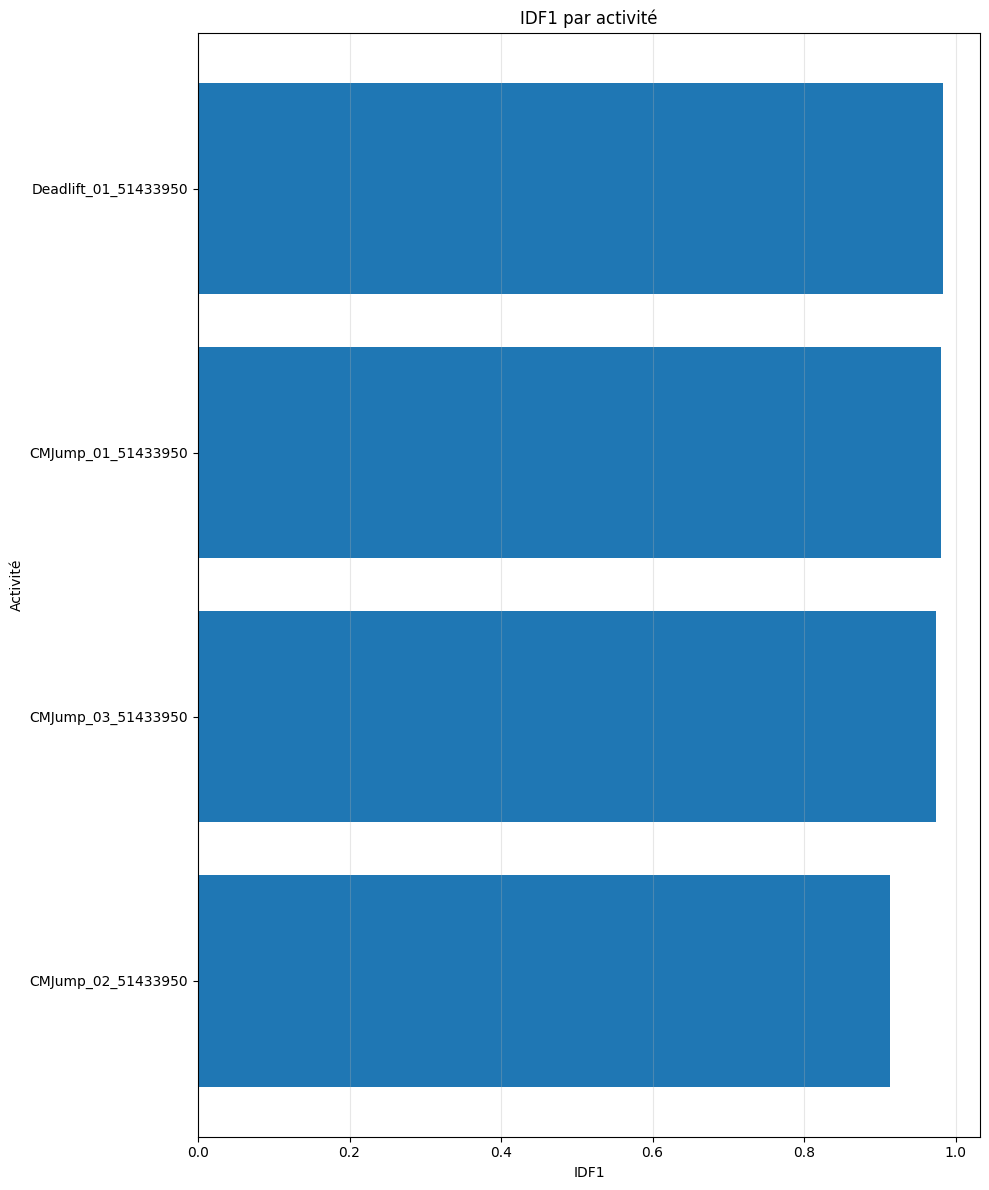

In [7]:
df_plot = df_activity.sort_values("idf1", ascending=True).reset_index(drop=True)

plt.figure(figsize=(10, 12))
plt.barh(df_plot["activity"], df_plot["idf1"])
plt.title("IDF1 par activité")
plt.xlabel("IDF1")
plt.ylabel("Activité")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
df_seq_no_overall = df_sequence[df_sequence.iloc[:, 0] != "OVERALL"].copy()
display(df_seq_no_overall.head())

,Unnamed: 0,n_frames,n_gt,n_pred,matches,IDs,FM,MT,PT,ML,FP,FN,precision,recall,mota,motp,idf1,idp,idr
0,CMJump_01_51433950_cam00,385,385,385,384,1,0,1,0,0,0,0,1.0,1.000000,0.997403,0.000000,0.997403,0.997403,0.997403
1,CMJump_01_51433950_cam01,418,1254,1176,1175,1,35,3,0,0,0,78,1.0,0.937799,0.937002,0.028445,0.962140,0.994048,0.932217
2,CMJump_01_51433950_cam02,417,417,417,417,0,0,1,0,0,0,0,1.0,1.000000,1.000000,0.000092,1.000000,1.000000,1.000000
3,CMJump_01_51433950_cam03,409,409,409,409,0,0,1,0,0,0,0,1.0,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000
4,CMJump_02_51433950_cam00,540,540,540,540,0,0,1,0,0,0,0,1.0,1.000000,1.000000,0.017675,1.000000,1.000000,1.000000


In [9]:
seq_name_col = df_seq_no_overall.columns[0]

extract = df_seq_no_overall[seq_name_col].str.extract(r"^(?P<activity>.+)_cam(?P<cam>\d{2})$")
df_seq_no_overall["activity"] = extract["activity"]
df_seq_no_overall["cam"] = extract["cam"]

display(df_seq_no_overall.head())

,Unnamed: 0,n_frames,n_gt,n_pred,matches,IDs,FM,MT,PT,ML,...,FN,precision,recall,mota,motp,idf1,idp,idr,activity,cam
0,CMJump_01_51433950_cam00,385,385,385,384,1,0,1,0,0,...,0,1.0,1.000000,0.997403,0.000000,0.997403,0.997403,0.997403,CMJump_01_51433950,00
1,CMJump_01_51433950_cam01,418,1254,1176,1175,1,35,3,0,0,...,78,1.0,0.937799,0.937002,0.028445,0.962140,0.994048,0.932217,CMJump_01_51433950,01
2,CMJump_01_51433950_cam02,417,417,417,417,0,0,1,0,0,...,0,1.0,1.000000,1.000000,0.000092,1.000000,1.000000,1.000000,CMJump_01_51433950,02
3,CMJump_01_51433950_cam03,409,409,409,409,0,0,1,0,0,...,0,1.0,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,CMJump_01_51433950,03
4,CMJump_02_51433950_cam00,540,540,540,540,0,0,1,0,0,...,0,1.0,1.000000,1.000000,0.017675,1.000000,1.000000,1.000000,CMJump_02_51433950,00


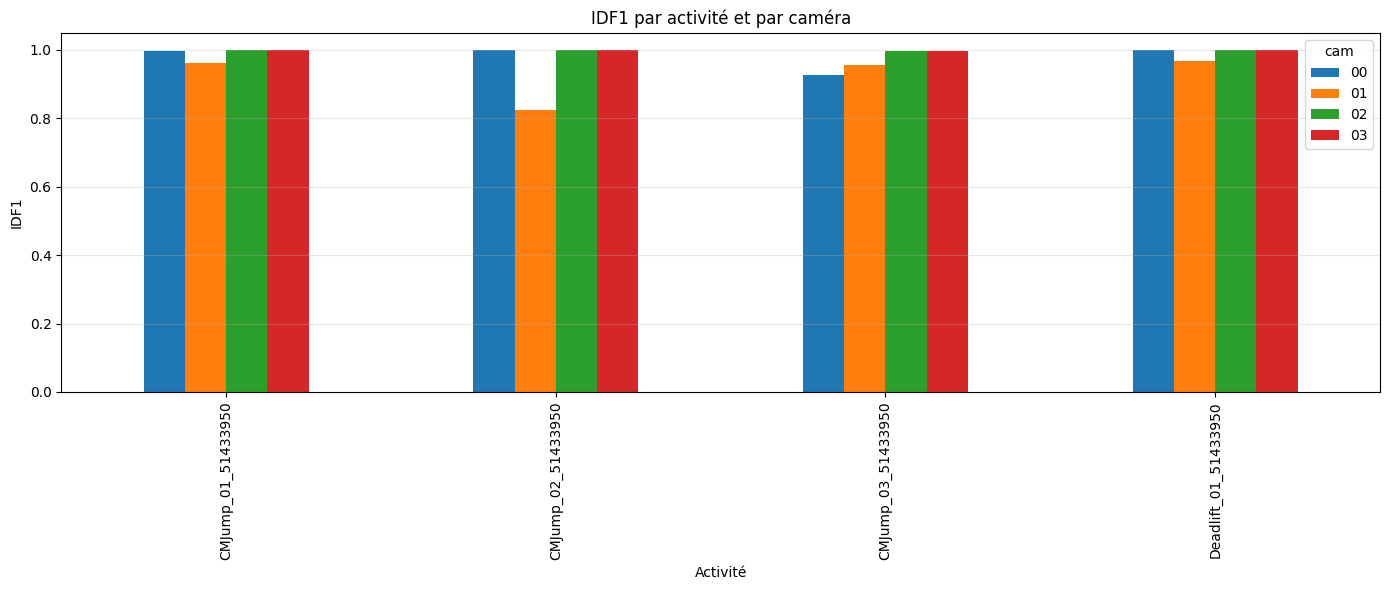

In [10]:
pivot_idf1 = df_seq_no_overall.pivot(index="activity", columns="cam", values="idf1")
pivot_idf1 = pivot_idf1.sort_index()

pivot_idf1.plot(kind="bar", figsize=(14, 6))
plt.title("IDF1 par activité et par caméra")
plt.xlabel("Activité")
plt.ylabel("IDF1")
plt.xticks(rotation=90)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

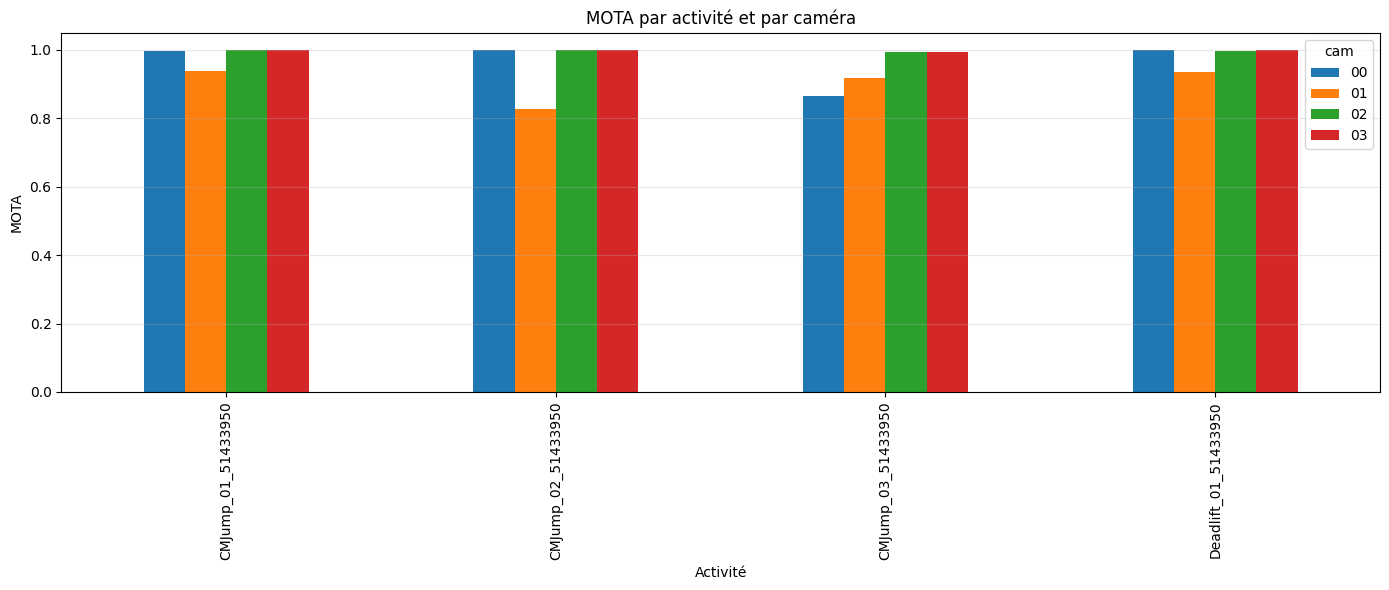

In [11]:
pivot_mota = df_seq_no_overall.pivot(index="activity", columns="cam", values="mota")
pivot_mota = pivot_mota.sort_index()

pivot_mota.plot(kind="bar", figsize=(14, 6))
plt.title("MOTA par activité et par caméra")
plt.xlabel("Activité")
plt.ylabel("MOTA")
plt.xticks(rotation=90)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

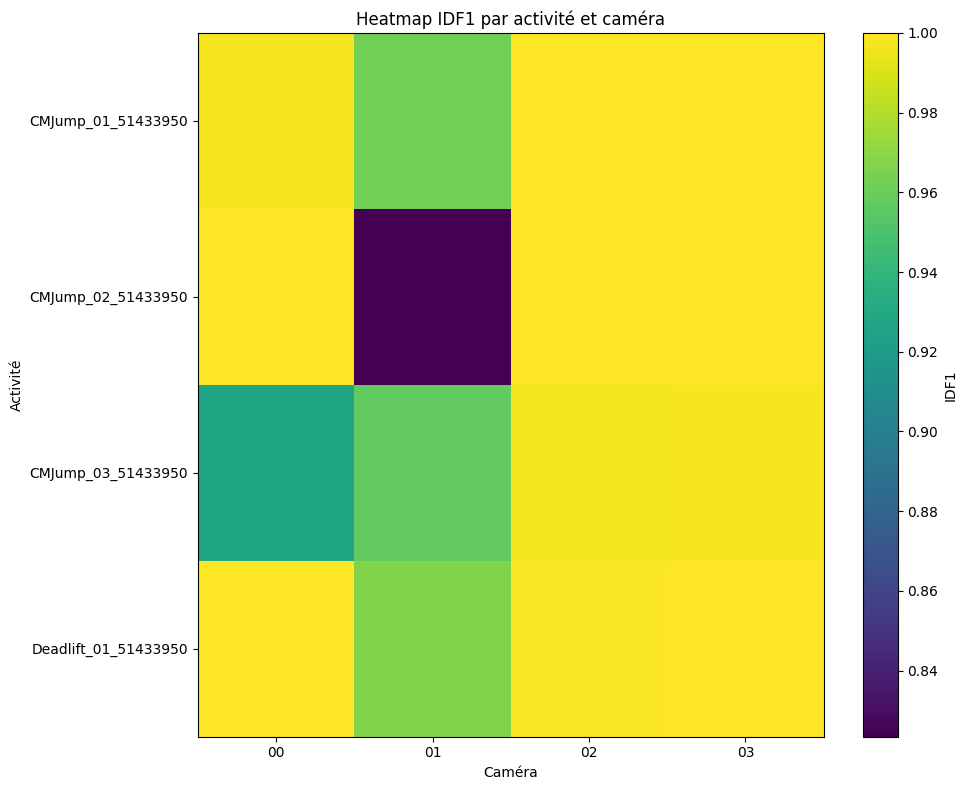

In [12]:
pivot_idf1 = df_seq_no_overall.pivot(index="activity", columns="cam", values="idf1")
pivot_idf1 = pivot_idf1.sort_index()

plt.figure(figsize=(10, 8))
plt.imshow(pivot_idf1.values, aspect="auto")
plt.colorbar(label="IDF1")
plt.title("Heatmap IDF1 par activité et caméra")
plt.xlabel("Caméra")
plt.ylabel("Activité")
plt.xticks(range(len(pivot_idf1.columns)), pivot_idf1.columns)
plt.yticks(range(len(pivot_idf1.index)), pivot_idf1.index)
plt.tight_layout()
plt.show()

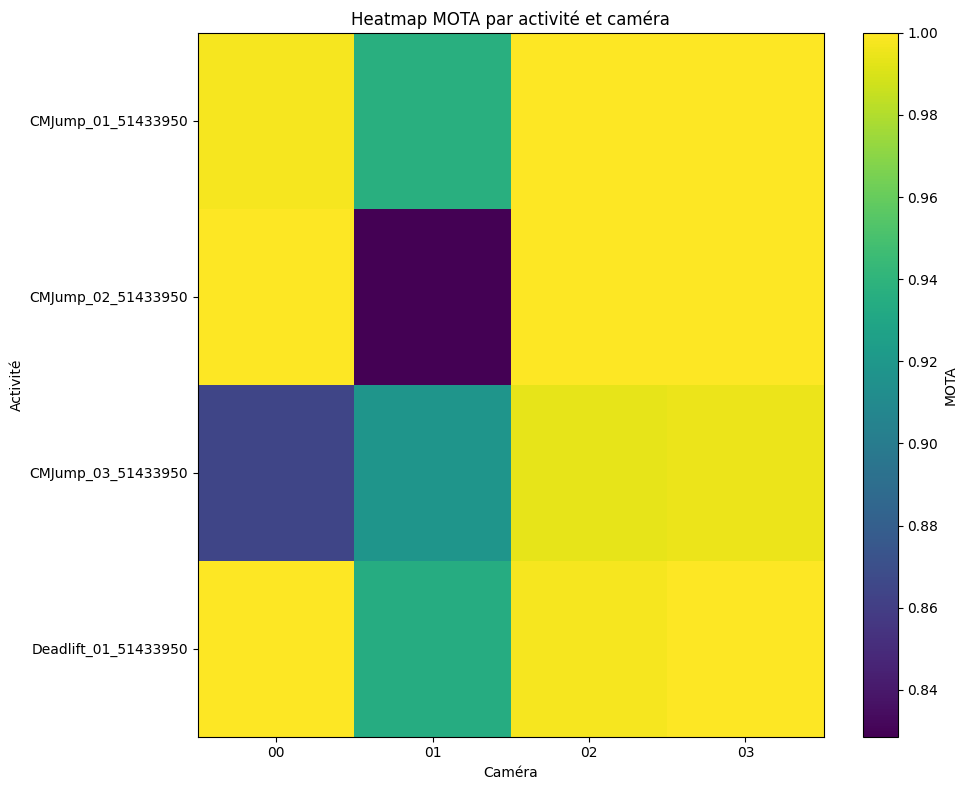

In [13]:
pivot_mota = df_seq_no_overall.pivot(index="activity", columns="cam", values="mota")
pivot_mota = pivot_mota.sort_index()

plt.figure(figsize=(10, 8))
plt.imshow(pivot_mota.values, aspect="auto")
plt.colorbar(label="MOTA")
plt.title("Heatmap MOTA par activité et caméra")
plt.xlabel("Caméra")
plt.ylabel("Activité")
plt.xticks(range(len(pivot_mota.columns)), pivot_mota.columns)
plt.yticks(range(len(pivot_mota.index)), pivot_mota.index)
plt.tight_layout()
plt.show()

C:\Users\zakar\AppData\Local\Temp\ipykernel_27060\2365137397.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels)
C:\Users\zakar\AppData\Local\Temp\ipykernel_27060\2365137397.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels)
C:\Users\zakar\AppData\Local\Temp\ipykernel_27060\2365137397.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels)
C:\Users\zakar\AppData\Local\Temp\ipykernel_27060\2365137397.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; 

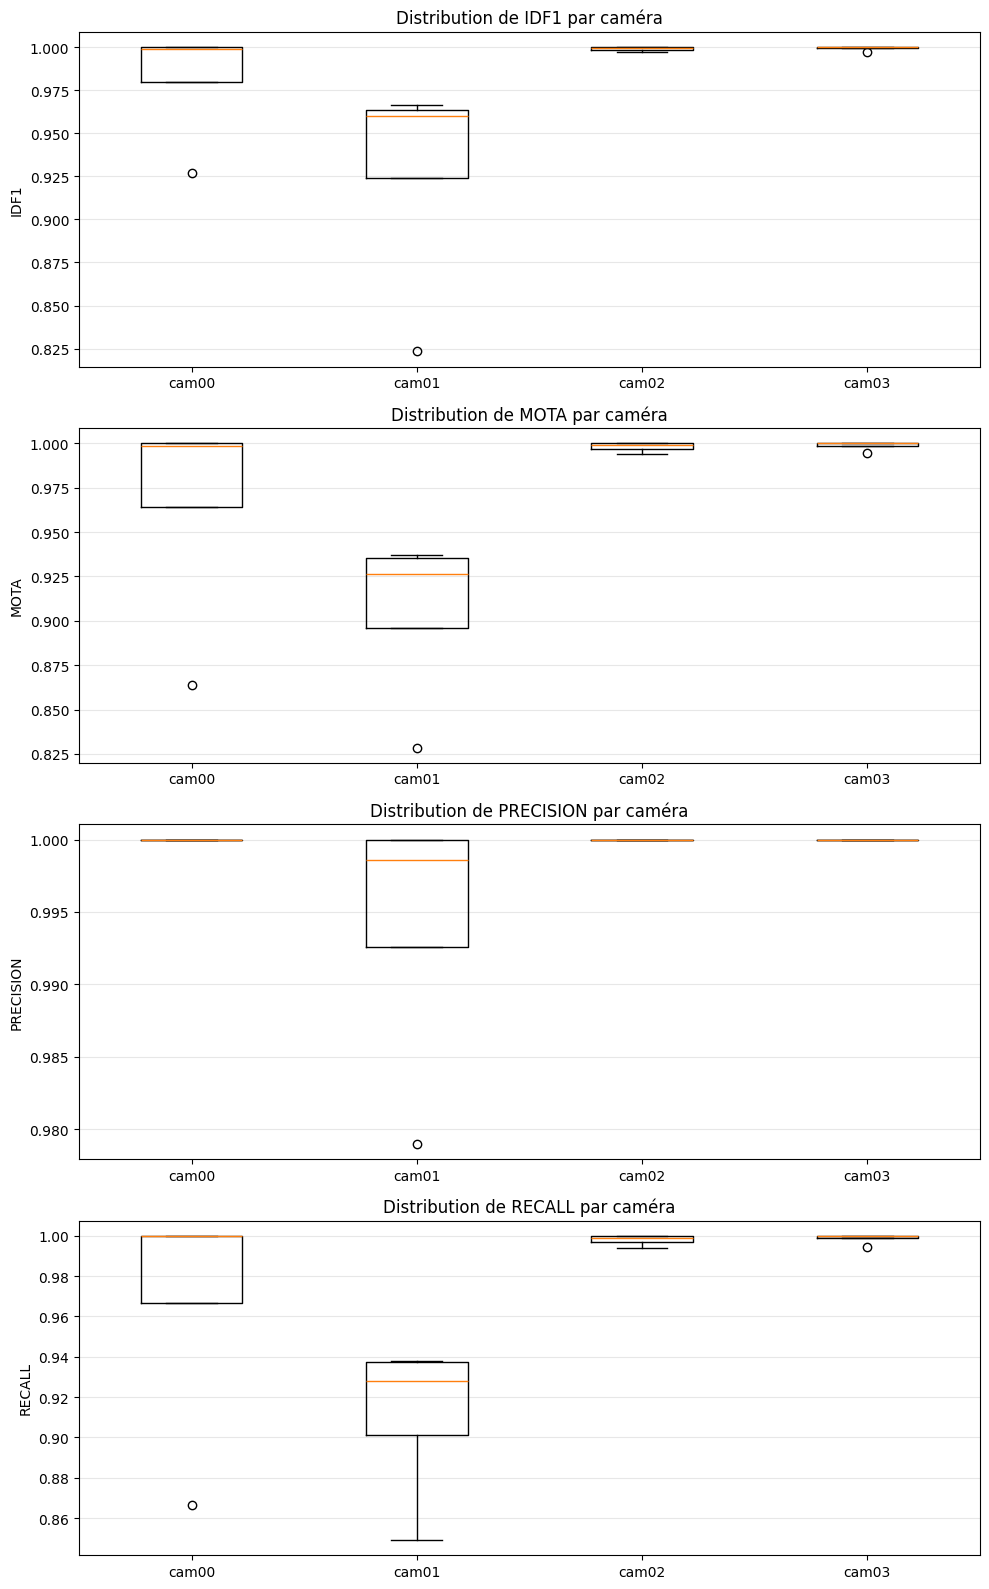

In [14]:
metrics_box = ["idf1", "mota", "precision", "recall"]

fig, axes = plt.subplots(len(metrics_box), 1, figsize=(10, 4 * len(metrics_box)))

if len(metrics_box) == 1:
    axes = [axes]

for ax, metric in zip(axes, metrics_box):
    data = []
    labels = []

    for cam in sorted(df_seq_no_overall["cam"].dropna().unique()):
        vals = df_seq_no_overall.loc[df_seq_no_overall["cam"] == cam, metric].dropna().values
        if len(vals) > 0:
            data.append(vals)
            labels.append(f"cam{cam}")

    if len(data) == 0:
        ax.set_visible(False)
        continue

    ax.boxplot(data, labels=labels)
    ax.set_title(f"Distribution de {metric.upper()} par caméra")
    ax.set_ylabel(metric.upper())
    ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
overall_row = df_sequence[df_sequence.iloc[:, 0] == "OVERALL"].copy()
display(overall_row)

,Unnamed: 0,n_frames,n_gt,n_pred,matches,IDs,FM,MT,PT,ML,FP,FN,precision,recall,mota,motp,idf1,idp,idr
16,OVERALL,8503,13814,13164,13120,8,172,23,4,0,36,686,0.997265,0.95034,0.947155,0.012162,0.962117,0.985871,0.939482


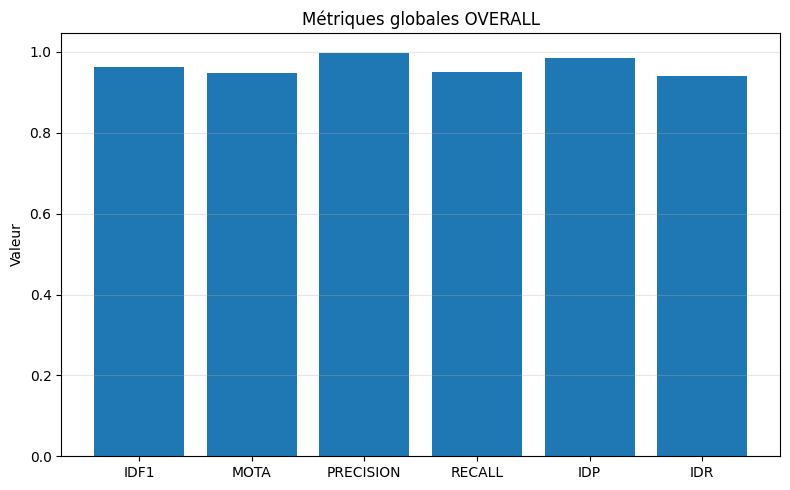

In [16]:
overall_metrics = ["idf1", "mota", "precision", "recall", "idp", "idr"]

overall_values = []
overall_labels = []

for metric in overall_metrics:
    if metric in overall_row.columns:
        overall_labels.append(metric.upper())
        overall_values.append(float(overall_row.iloc[0][metric]))

plt.figure(figsize=(8, 5))
plt.bar(overall_labels, overall_values)
plt.title("Métriques globales OVERALL")
plt.ylabel("Valeur")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

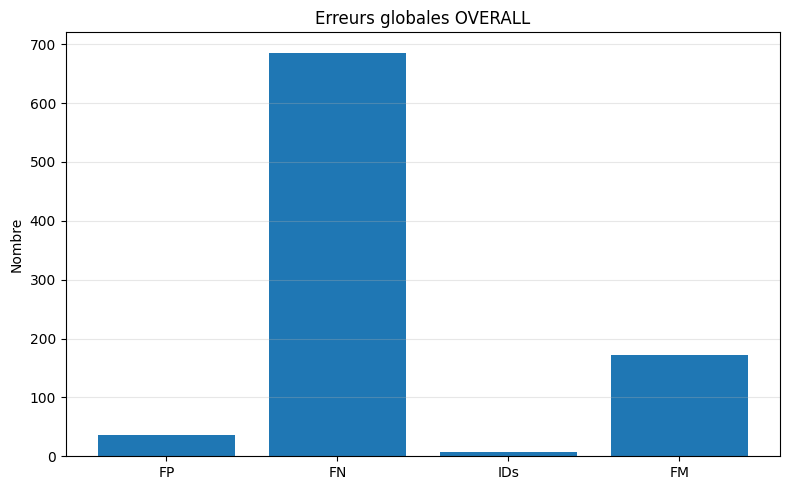

In [17]:
overall_error_metrics = ["FP", "FN", "IDs", "FM"]

overall_values = []
overall_labels = []

for metric in overall_error_metrics:
    if metric in overall_row.columns:
        overall_labels.append(metric)
        overall_values.append(float(overall_row.iloc[0][metric]))

plt.figure(figsize=(8, 5))
plt.bar(overall_labels, overall_values)
plt.title("Erreurs globales OVERALL")
plt.ylabel("Nombre")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
FIG_DIR = OUTPUT_DIR / "figures_tracking"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Dossier figures :", FIG_DIR)

Dossier figures : eval_tracking_subject12\figures_tracking


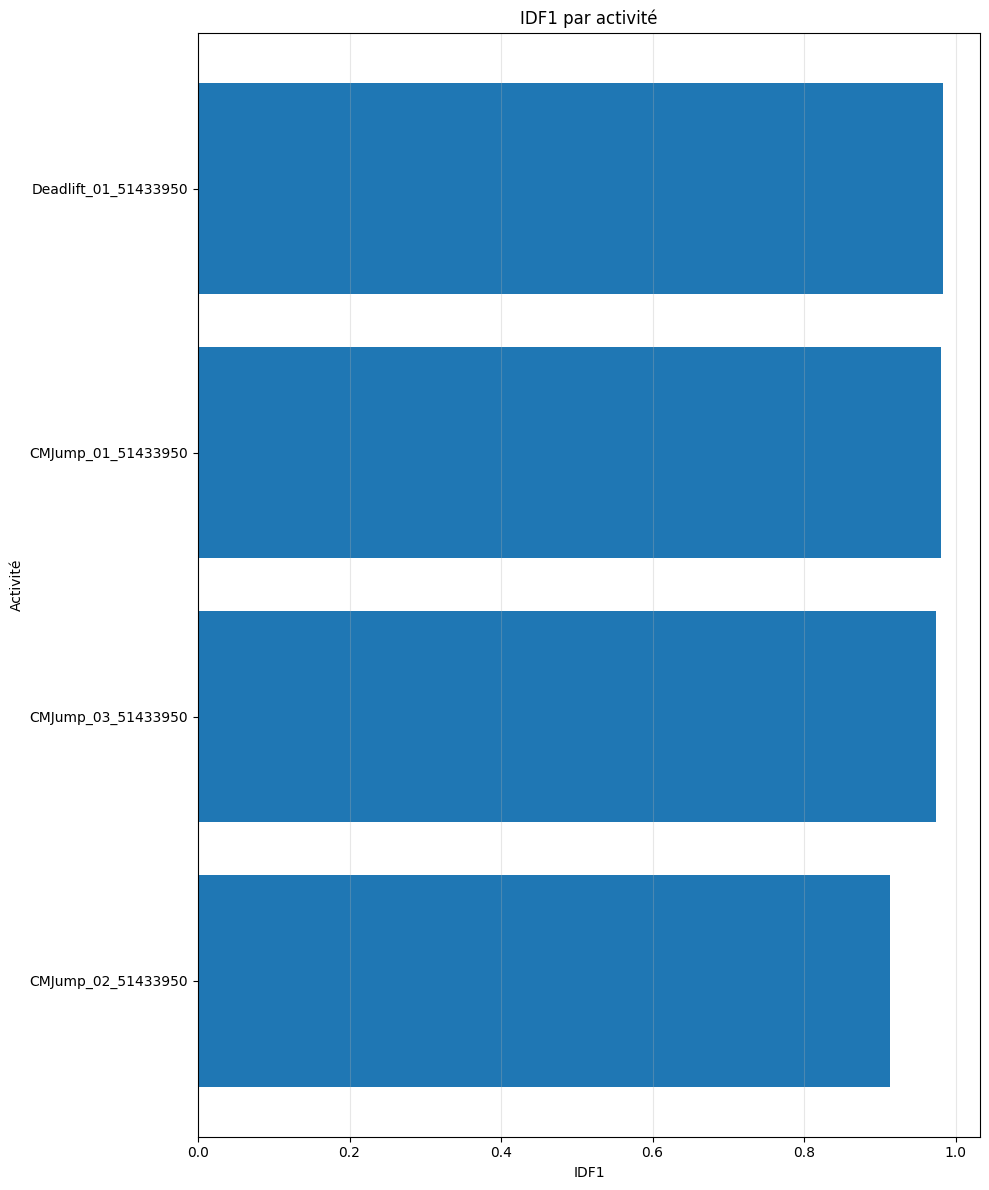

In [19]:
df_plot = df_activity.sort_values("idf1", ascending=True).reset_index(drop=True)

plt.figure(figsize=(10, 12))
plt.barh(df_plot["activity"], df_plot["idf1"])
plt.title("IDF1 par activité")
plt.xlabel("IDF1")
plt.ylabel("Activité")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "idf1_par_activite.png", dpi=200, bbox_inches="tight")
plt.show()

In [20]:
cols = ["activity", "idf1", "mota", "precision", "recall", "FP", "FN", "IDs", "FM"]
cols = [c for c in cols if c in df_activity.columns]

df_final = df_activity[cols].sort_values("idf1", ascending=False).reset_index(drop=True)
display(df_final)

,activity,idf1,mota,precision,recall,FP,FN,IDs,FM
0,Deadlift_01_51433950,0.983080,0.966678,0.998597,0.968038,4.0,94.0,0.0,31.0
1,CMJump_01_51433950,0.980627,0.967546,1.000000,0.968357,0.0,78.0,2.0,35.0
2,CMJump_03_51433950,0.973992,0.949293,1.000000,0.949697,0.0,249.0,2.0,38.0
3,CMJump_02_51433950,0.913362,0.912955,0.990078,0.923366,32.0,265.0,4.0,68.0
